# CAP182 SS3 Part B: Applying Logistic Regression to Client Data

In [17]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## Dataset loading

Load the five data extracts then inspect their dimensions and data types and establish the target classes and imbalances.

In [18]:
RANDOM_STATE = 42
DATA_DIR = Path("../Datasets/Client Data")

FILE_CANDIDATES = {
    "orders": ["table1_orders_transactions.csv", "table1_orders_transactions(1).csv"],
    "customer": ["table2_customer_behaviour.csv", "table2_customer_behaviour(1).csv"],
    "returns": ["table3_return_outcomes.csv"],
    "products": ["table4_product_reference.csv"],
    "sellers": ["table5_seller_reference.csv"],}

def locate_csv(candidates):
    search_dirs = [DATA_DIR, Path("."), Path("/mnt/data")]
    for folder in search_dirs:
        for filename in candidates:
            candidate = folder / filename
            if candidate.exists():
                return candidate

paths = {name: locate_csv(names) for name, names in FILE_CANDIDATES.items()}
data = {name: pd.read_csv(path) for name, path in paths.items()}

for name, df in data.items():
    print(f"{name.title():<10} | file={paths[name].name} | rows={len(df):,} | columns={df.shape[1]}")

orders_raw = data["orders"].copy()
customer_raw = data["customer"].copy()
returns_raw = data["returns"].copy()
products_raw = data["products"].copy()
sellers_raw = data["sellers"].copy()

print("\nRaw table dimensions:")
display(pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1], "duplicate_rows": int(df.duplicated().sum())}
                       for name, df in data.items()}).T)

print("\nTarget column preview:")
print(returns_raw["returned"].value_counts(dropna=False))

Orders     | file=table1_orders_transactions.csv | rows=17,877 | columns=16
Customer   | file=table2_customer_behaviour.csv | rows=17,842 | columns=13
Returns    | file=table3_return_outcomes.csv | rows=17,842 | columns=10
Products   | file=table4_product_reference.csv | rows=1,487 | columns=10
Sellers    | file=table5_seller_reference.csv | rows=214 | columns=5

Raw table dimensions:


,rows,columns,duplicate_rows
orders,17877,16,35
customer,17842,13,0
returns,17842,10,0
products,1487,10,0
sellers,214,5,0



Target column preview:
returned
False    14438
True      3404
Name: count, dtype: int64


### Dataset Exploration

The supplied Return Outcomes table contains 17,842 order instances. The target is returned, a binary label where False means the order was not returned and True means it was returned. In this extract 14,438 orders were not returned (80.92%) and 3,404 were returned (19.08%). The target appears to be quite imbalanced,thus, accuracy alone would not be an adequate evaluation measure. 

Exact duplicate order rows in the Orders/Transactions table are investigated and removed before joining, so one order contributes one modelling instance. The class proportions are recalculated after integration to confirm that no target rows were lost.

Return-outcome instances: 17,842
Not returned (False): 14,438 (80.92%)
Returned (True): 3,404 (19.08%)


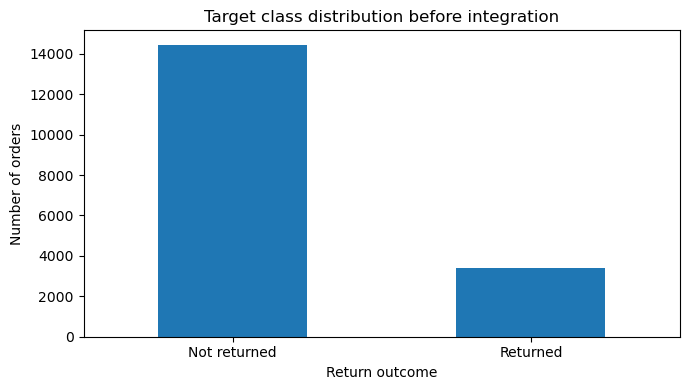


Orders table data types:


,dtype
order_id,object
customer_id,object
order_datetime,object
prd_id,object
seller_id,object
quantity,int64
unit_price,float64
discount_amount,float64
promotion_code,object
payment_method,object


In [19]:
target_counts_raw = returns_raw["returned"].value_counts(dropna=False).rename(index={False: "Not returned (False)", True: "Returned (True)"})
target_props_raw = returns_raw["returned"].value_counts(normalize=True, dropna=False)
print(f"Return-outcome instances: {len(returns_raw):,}")
for label, count in target_counts_raw.items():
    print(f"{label}: {count:,} ({count / len(returns_raw):.2%})")

fig, ax = plt.subplots(figsize=(7, 4))
plot_counts = returns_raw["returned"].map({False: "Not returned", True: "Returned"}).value_counts()
plot_counts.plot(kind="bar", ax=ax)
ax.set_title("Target class distribution before integration")
ax.set_xlabel("Return outcome")
ax.set_ylabel("Number of orders")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print("\nOrders table data types:")
display(orders_raw.dtypes.rename("dtype").to_frame())

## Dataset Preprocessing
1. **Remove only exact duplicate transaction rows.** The Orders/Transactions table contains repeated rows with the same order ID and identical field values. Keeping them would duplicate observations and could distort model evaluation.
2. **Validate join keys and join cardinality.** The transaction table is the starting point. Customer behaviour is joined by order_id, return outcomes contribute only the target label, product information is joined by prd_id, and seller information is joined by seller_id.
3. **Address the seller-reference key issue transparently.** The supplied seller table has repeated rows with conflicting numeric values. To allow a many-to-one join without arbitrarily choosing one row, numeric seller fields are averaged for that ID and the categorical seller type uses its mode. 
4. **Prevent target leakage.** Return date, return reason, days to return, refund amount/status, returned quantity and item condition are not used as predictors because they are only known after the return process.
5. **Create date-derived features and remove identifiers.** Order hour, day of week, month and year are extracted from the order timestamp. IDs are retained only for joins and are not model features.
6. **Impute and encode within a scikit-learn pipeline.** Numeric missing values are median-imputed and scaled; categorical missing values are filled with the most frequent category and one-hot encoded. Fitting the pipeline on training data only prevents information from validation/test sets leaking into preprocessing.
7. **Use stratified train/validation/test splits.** Stratification preserves the approximate target proportions across the subsets.

#### Remove Duplicates and prepare for joining

In [20]:
# Work on copies so the raw data remains the same
orders = orders_raw.copy()
customer = customer_raw.copy()
returns = returns_raw.copy()
products = products_raw.copy()
sellers = sellers_raw.copy()

# Normalise join-key strings
for df, cols in [
    (orders, ["order_id", "customer_id", "prd_id", "seller_id"]),
    (customer, ["order_id", "customer_id"]),
    (returns, ["order_id", "prd_id"]),
    (products, ["prd_id", "seller_id"]),
    (sellers, ["seller_id"]),]:
    for col in cols:
        if col in df.columns:
            df[col] = df[col].astype("string").str.strip()

print(f"Orders before exact-duplicate removal: {len(orders):,}")
print(f"Exact duplicate rows in Orders: {orders.duplicated().sum():,}")
orders = orders.drop_duplicates().copy()
print(f"Orders after exact-duplicate removal: {len(orders):,}")
print(f"Unique order IDs after cleaning: {orders['order_id'].nunique():,}")

# Check key uniqueness before joining
assert orders["order_id"].is_unique, "Order IDs are still duplicated after exact duplicate removal."
assert customer["order_id"].is_unique, "Customer behaviour must have one row per order."
assert returns["order_id"].is_unique, "Return outcomes must have one row per order."
assert products["prd_id"].is_unique, "Product reference IDs must be unique."

# Check whether the order and return tables share product IDs.
return_product_check = orders[["order_id", "prd_id"]].merge(
    returns[["order_id", "prd_id"]], on="order_id", how="left", suffixes=("_order", "_return"), validate="one_to_one")
product_id_mismatches = (return_product_check["prd_id_order"] != return_product_check["prd_id_return"]).sum()
print(f"Order/return product-ID mismatches: {product_id_mismatches:,}")

# Keep the target from only the outcomes table as other outcome fields may leak future information.
return_labels = returns[["order_id", "returned"]].copy()
return_labels["returned"] = return_labels["returned"].astype("int8")

# Drop the duplicate customer ID from behaviour as the transaction table already contains it
customer_features = customer.drop(columns=["customer_id"], errors="ignore")

# Product reference seller_id duplicates the seller identifier already in Orders.
product_features = products.drop(columns=["seller_id"], errors="ignore")

# Resolve the repeated seller ID using a documented aggregation instead of arbitrary drop_duplicates.
seller_duplicate_ids = sellers.loc[sellers["seller_id"].duplicated(keep=False), "seller_id"].unique().tolist()
print(f"Seller IDs with repeated rows: {seller_duplicate_ids}")

seller_numeric = [c for c in ["seller_rating", "avg_dispatch_days", "years_on_platform"] if c in sellers.columns]
seller_categorical = [c for c in ["seller_type"] if c in sellers.columns]
agg = {col: "mean" for col in seller_numeric}
for col in seller_categorical:
    agg[col] = lambda x: x.mode().iloc[0] if not x.mode().empty else x.iloc[0]
sellers_unique = sellers.groupby("seller_id", as_index=False).agg(agg)
assert sellers_unique["seller_id"].is_unique

# Confirm reference coverage before merging.
print("Orders missing customer-behaviour match:", len(set(orders.order_id) - set(customer_features.order_id)))
print("Orders missing return-label match:", len(set(orders.order_id) - set(return_labels.order_id)))
print("Orders missing product match:", len(set(orders.prd_id) - set(products.prd_id)))
print("Orders missing seller match:", len(set(orders.seller_id) - set(sellers_unique.seller_id)))

Orders before exact-duplicate removal: 17,877
Exact duplicate rows in Orders: 35
Orders after exact-duplicate removal: 17,842
Unique order IDs after cleaning: 17,842
Order/return product-ID mismatches: 0
Seller IDs with repeated rows: ['SEL00001']
Orders missing customer-behaviour match: 0
Orders missing return-label match: 0
Orders missing product match: 0
Orders missing seller match: 0


#### Complete joining

In [21]:
# Join in a controlled sequence.
df = orders.merge(customer_features, on="order_id", how="left", validate="one_to_one")
df = df.merge(return_labels, on="order_id", how="left", validate="one_to_one")
df = df.merge(product_features, on="prd_id", how="left", validate="many_to_one")
df = df.merge(sellers_unique, on="seller_id", how="left", validate="many_to_one")

if df["returned"].isna().any():
    raise ValueError("Some transactions have no return label. Investigate joins before modelling.")
if product_id_mismatches:
    warnings.warn("Some order and return product IDs do not match. Investigate these records.")

print(f"\nIntegrated modelling table: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("Unique order IDs:", df["order_id"].nunique())
print("Missing target labels:", df["returned"].isna().sum())


Integrated modelling table: 17,842 rows × 40 columns
Unique order IDs: 17842
Missing target labels: 0


#### Continued data cleaning and Feature Engineering

In [22]:
# Derive order-time features before removing the raw timestamp
df["order_datetime"] = pd.to_datetime(df["order_datetime"], errors="coerce")
df["order_hour"] = df["order_datetime"].dt.hour
df["order_dayofweek"] = df["order_datetime"].dt.dayofweek
df["order_month"] = df["order_datetime"].dt.month
df["order_year"] = df["order_datetime"].dt.year
df = df.drop(columns=["order_datetime"], errors="ignore")

# Treat postal codes as categorical
if "delivery_postal_area" in df.columns:
    df["delivery_postal_area"] = df["delivery_postal_area"].astype("Int64").astype("string")

# Remove post-outcome fields if present to prevent leakage.
post_outcome_columns = [
    "return_datetime", "days_to_return", "return_quantity", "return_reason",
    "item_condition", "refund_amount", "refund_status"]
df = df.drop(columns=post_outcome_columns, errors="ignore")

# IDs are join keys only and are excluded from the predictor variables.
identifier_columns = ["order_id", "customer_id", "prd_id", "seller_id"]
X = df.drop(columns=["returned"] + identifier_columns, errors="ignore").copy()
y = df["returned"].astype(int).copy()

# Convert any remaining boolean predictors to strings so the categorical pipeline handles them consistently.
for col in X.select_dtypes(include=["bool"]).columns:
    X[col] = X[col].astype(str)

# Convert pandas nullable string values to np.nan for sklearn imputers.
for col in X.select_dtypes(include=["object", "string", "category"]).columns:
    X[col] = X[col].astype(object)
    X[col] = X[col].where(pd.notna(X[col]), np.nan)

# Determine feature types from the integrated data.
categorical_features = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
numeric_features = [col for col in X.columns if col not in categorical_features]

print(f"Predictor count: {X.shape[1]}")
print(f"Numeric predictors ({len(numeric_features)}): {numeric_features}")
print(f"Categorical predictors ({len(categorical_features)}): {categorical_features}")
print("\nMissing values in predictors (top 15):")
display(X.isna().sum().sort_values(ascending=False).head(15).rename("missing_count").to_frame())

print("\nFinal class distribution:")
class_counts = y.value_counts().sort_index()
class_names = {0: "Not returned (0)", 1: "Returned (1)"}
for label, count in class_counts.items():
    print(f"{class_names[label]}: {count:,} ({count / len(y):.2%})")

Predictor count: 38
Numeric predictors (25): ['quantity', 'unit_price', 'discount_amount', 'order_value', 'basket_size', 'account_age_days', 'previous_orders', 'previous_returns', 'previous_return_rate', 'previous_purchase_value', 'days_since_previous_order', 'session_searches', 'product_views', 'add_to_basket_count', 'abandoned_baskets', 'list_price', 'product_rating', 'review_count', 'seller_rating', 'avg_dispatch_days', 'years_on_platform', 'order_hour', 'order_dayofweek', 'order_month', 'order_year']
Categorical predictors (13): ['promotion_code', 'payment_method', 'delivery_province', 'delivery_postal_area', 'device_type', 'channel', 'customer_segment', 'category', 'subcategory', 'brand', 'colour', 'size', 'seller_type']

Missing values in predictors (top 15):


,missing_count
size,10576
days_since_previous_order,4074
device_type,569
delivery_postal_area,237
order_month,185
order_year,185
order_dayofweek,185
order_hour,185
delivery_province,0
payment_method,0



Final class distribution:
Not returned (0): 14,438 (80.92%)
Returned (1): 3,404 (19.08%)


#### Training/Validation/Test Split

In [23]:
# Split into 70% training, 15% validation and 15% test, with class stratification.
from sklearn.model_selection import train_test_split

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y)
validation_fraction_of_trainval = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=validation_fraction_of_trainval,
    random_state=RANDOM_STATE, stratify=y_trainval)

split_summary = pd.DataFrame({
    "subset": ["Training", "Validation", "Test"],
    "instances": [len(y_train), len(y_val), len(y_test)],
    "returned_count": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "returned_percent": [100 * y_train.mean(), 100 * y_val.mean(), 100 * y_test.mean()],})
display(split_summary.round(2))

assert set(X_train.index).isdisjoint(set(X_val.index))
assert set(X_train.index).isdisjoint(set(X_test.index))
assert set(X_val.index).isdisjoint(set(X_test.index))

,subset,instances,returned_count,returned_percent
0,Training,12488,2382,19.07
1,Validation,2677,511,19.09
2,Test,2677,511,19.09


### Preprocessing Pipeline
A simple preprocessing pipeline that will be applied to the training data

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),], remainder="drop")

## Model Training
Logistic Regression is retained as the primary method based on the performance results of SS2. It is a supervised binary classifier and provides class probabilities that can be evaluated at a defined threshold.

- **C=1.0:** a standard baseline inverse-regularisation strength. It provides regularisation while avoiding an arbitrary extreme setting.
- **max_iter=2000:** provides sufficient iterations for the solver to converge with one-hot encoded features.
- **class_weight="balanced":** compensates for the smaller returned-order class by weighting classes inversely to their frequencies. This is intended to improve attention to the minority class, though it may reduce precision and must be evaluated rather than assumed beneficial.
- **random_state=42:** supports reproducibility.

In [25]:
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=2000,
        class_weight="balanced",
        solver="lbfgs",
        random_state=RANDOM_STATE,)),])

model.fit(X_train, y_train)
print("Logistic Regression training complete.")
print("Training instances:", len(X_train))
print("Validation instances:", len(X_val))
print("Held-out test instances:", len(X_test))

Logistic Regression training complete.
Training instances: 12488
Validation instances: 2677
Held-out test instances: 2677


## Model Validation
The validation set provides an initial development check. The test set remains unseen during fitting and model selection and is used for the final evaluation. Accuracy is reported, but it is not treated as the only measure because returned orders are the minority class. Precision, recall, F1-score, ROC-AUC and average precision provide a more informative view of return detection.

In [27]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report)

def evaluate_subset(name, X_subset, y_subset, fitted_model):
    predictions = fitted_model.predict(X_subset)
    probabilities = fitted_model.predict_proba(X_subset)[:, 1]
    return {
        "subset": name,
        "accuracy": accuracy_score(y_subset, predictions),
        "precision_returned": precision_score(y_subset, predictions, zero_division=0),
        "recall_returned": recall_score(y_subset, predictions, zero_division=0),
        "f1_returned": f1_score(y_subset, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_subset, probabilities),
        "average_precision": average_precision_score(y_subset, probabilities),
        "predictions": predictions,
        "probabilities": probabilities,}

train_results = evaluate_subset("Training", X_train, y_train, model)
val_results = evaluate_subset("Validation", X_val, y_val, model)
test_results = evaluate_subset("Test (unseen)", X_test, y_test, model)

metric_columns = ["accuracy", "precision_returned", "recall_returned", "f1_returned", "roc_auc", "average_precision"]
metrics_table = pd.DataFrame([
    {"subset": result["subset"], **{metric: result[metric] for metric in metric_columns}}
    for result in [train_results, val_results, test_results]]).set_index("subset")
display(metrics_table.round(4))

print("\nFinal held-out test classification report:")
print(classification_report(
    y_test, test_results["predictions"],
    target_names=["Not returned", "Returned"], zero_division=0))

print("Held-out test confusion matrix (rows=true, columns=predicted):")
cm = confusion_matrix(y_test, test_results["predictions"], labels=[0, 1])
display(pd.DataFrame(cm, index=["Actual not returned", "Actual returned"],
                     columns=["Predicted not returned", "Predicted returned"]))

,accuracy,precision_returned,recall_returned,f1_returned,roc_auc,average_precision
subset,,,,,,
Training,0.8174,0.5130,0.8463,0.6388,0.9061,0.6610
Validation,0.7318,0.3678,0.5636,0.4451,0.7290,0.3981
Test (unseen),0.7090,0.3378,0.5460,0.4174,0.7159,0.3836



Final held-out test classification report:
              precision    recall  f1-score   support

Not returned       0.87      0.75      0.81      2166
    Returned       0.34      0.55      0.42       511

    accuracy                           0.71      2677
   macro avg       0.61      0.65      0.61      2677
weighted avg       0.77      0.71      0.73      2677

Held-out test confusion matrix (rows=true, columns=predicted):


,Predicted not returned,Predicted returned
Actual not returned,1619,547
Actual returned,232,279


## Results Visualisations
The following visualisations compare training, validation and unseen test performance and show where the test predictions succeed or fail. These results should be interpreted alongside the numeric metrics, particularly recall and precision for returned orders.

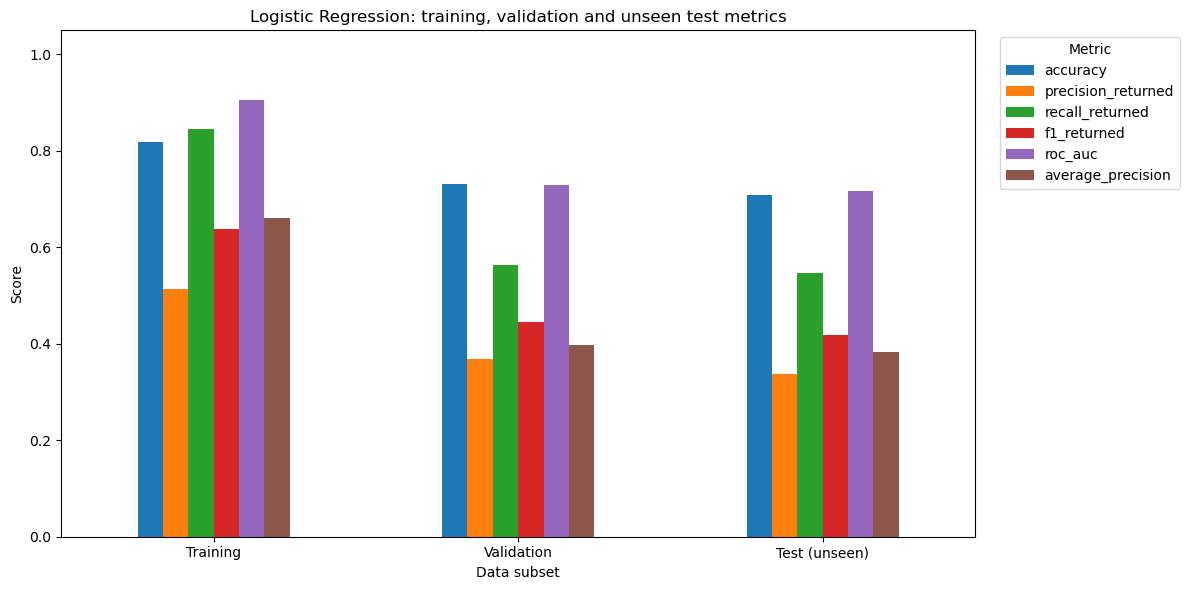

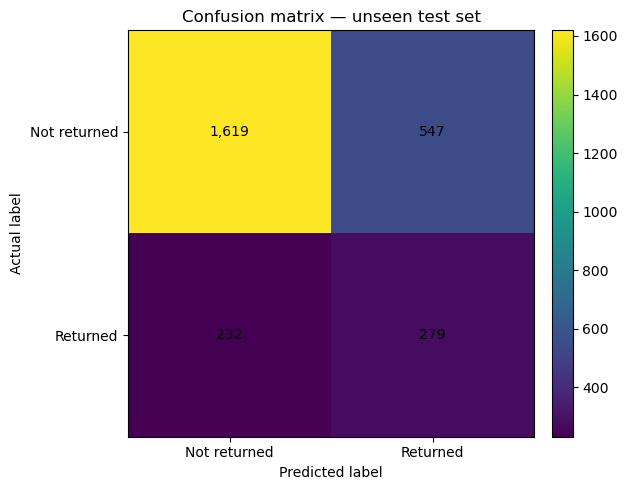

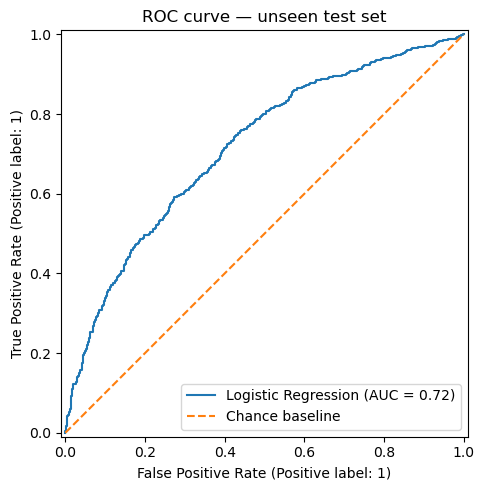

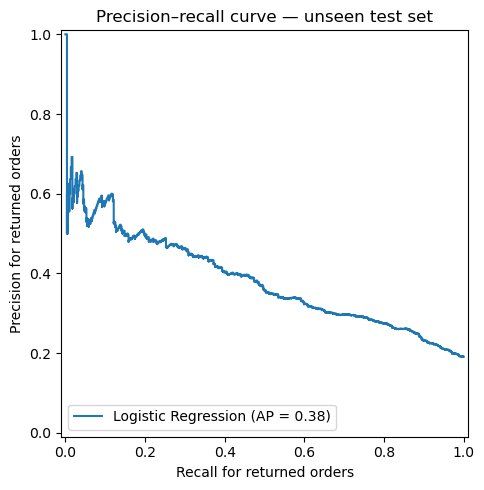

In [28]:
# Compare training, validation and test metrics.
metrics_to_plot = ["accuracy", "precision_returned", "recall_returned", "f1_returned", "roc_auc", "average_precision"]
metrics_table[metrics_to_plot].plot(kind="bar", figsize=(12, 6))
plt.title("Logistic Regression: training, validation and unseen test metrics")
plt.ylabel("Score")
plt.xlabel("Data subset")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Confusion matrix heatmap
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(cm, interpolation="nearest")
ax.set_title("Confusion matrix — unseen test set")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_xticks([0, 1], labels=["Not returned", "Returned"])
ax.set_yticks([0, 1], labels=["Not returned", "Returned"])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
# ROC curve
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, test_results["probabilities"], ax=ax, name="Logistic Regression")
ax.plot([0, 1], [0, 1], linestyle="--", label="Chance baseline")
ax.set_title("ROC curve — unseen test set")
ax.legend()
plt.tight_layout()
plt.show()

# Precision-recall curve
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, test_results["probabilities"], ax=ax, name="Logistic Regression")
ax.set_title("Precision–recall curve — unseen test set")
ax.set_xlabel("Recall for returned orders")
ax.set_ylabel("Precision for returned orders")
plt.tight_layout()
plt.show()

Features most associated with predicting a return (largest positive coefficients):


,coefficient
categorical__delivery_postal_area_3932,2.188912
categorical__delivery_postal_area_6841,1.875698
categorical__delivery_postal_area_3745,1.816502
categorical__delivery_postal_area_2041,1.813016
categorical__delivery_postal_area_5290,1.798593
categorical__delivery_postal_area_8035,1.786565
categorical__delivery_postal_area_3406,1.726006
categorical__delivery_postal_area_3761,1.717018
categorical__delivery_postal_area_2592,1.698583
categorical__delivery_postal_area_7594,1.691880


Features most associated with predicting no return (largest negative coefficients):


,coefficient
categorical__delivery_postal_area_1885,-1.358192
categorical__delivery_province_ Gauteng,-1.322033
categorical__payment_method_Instant EFT,-1.308247
categorical__delivery_postal_area_1638,-1.235464
categorical__delivery_postal_area_1748,-1.206269
categorical__delivery_postal_area_2044,-1.166705
categorical__delivery_postal_area_3379,-1.166461
categorical__delivery_postal_area_1819,-1.155258
numeric__unit_price,-1.138242
categorical__delivery_postal_area_2088,-1.128931


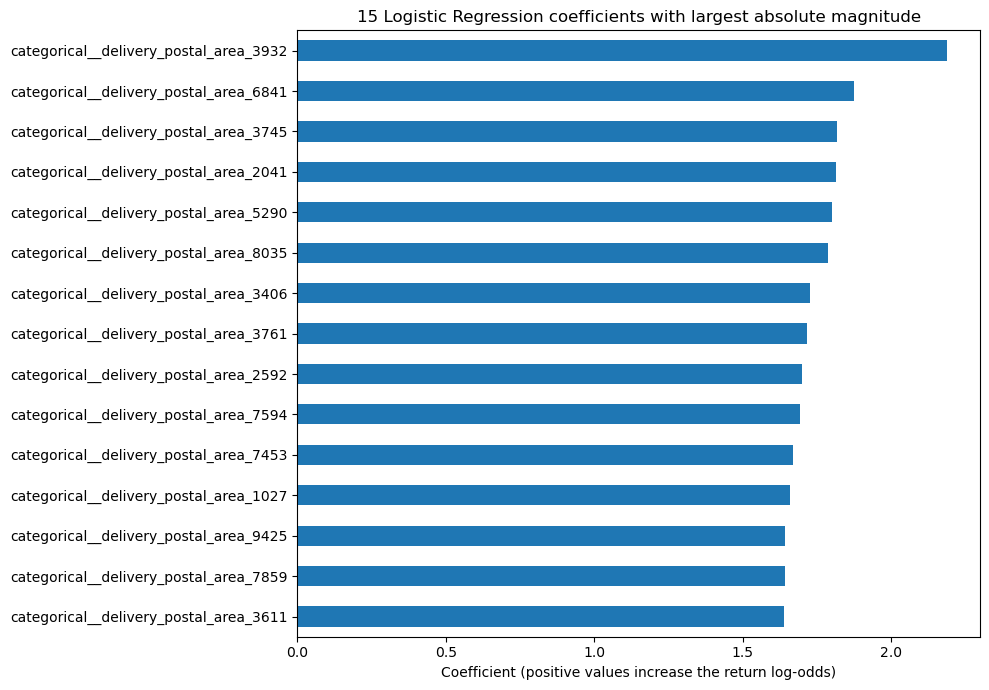

In [29]:
# Inspect the largest positive and negative Logistic Regression coefficients.
preprocessor_fitted = model.named_steps["preprocessing"]
classifier_fitted = model.named_steps["classifier"]
feature_names = preprocessor_fitted.get_feature_names_out()
coefficients = pd.Series(classifier_fitted.coef_[0], index=feature_names)

print("Features most associated with predicting a return (largest positive coefficients):")
display(coefficients.sort_values(ascending=False).head(12).rename("coefficient").to_frame())
print("Features most associated with predicting no return (largest negative coefficients):")
display(coefficients.sort_values(ascending=True).head(12).rename("coefficient").to_frame())

ax = coefficients.reindex(coefficients.abs().sort_values(ascending=False).head(15).index).sort_values().plot(
    kind="barh", figsize=(10, 7))
ax.set_title("15 Logistic Regression coefficients with largest absolute magnitude")
ax.set_xlabel("Coefficient (positive values increase the return log-odds)")
plt.tight_layout()
plt.show()